# OCT Preprocessing Pipeline

This notebook defines and validates the first reusable preprocessing pipeline for the AMD Digital Twin project. It loads the patient-level train, validation, and test CSV files, preprocesses OCT images to model-ready arrays, and saves only analysis tables and visualizations.

No model training is performed and no raw image is modified.

## 1. Environment and project paths

The reusable implementation lives in `src/oct_preprocessing.py`. It uses Pillow and NumPy so it can later be adapted to PyTorch, TensorFlow, or another model framework without coupling preprocessing to training.

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "OCTDL").is_dir():
            return candidate
    raise FileNotFoundError("Could not find a project root containing data/raw/OCTDL.")

PROJECT_ROOT = find_project_root()
SRC_ROOT = PROJECT_ROOT / "src"
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from oct_preprocessing import (
    IMAGE_SIZE,
    denormalize_image,
    preprocess_image,
    validate_preprocessed_array,
)

PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
OUTPUT_ROOT = PROCESSED_ROOT / "preprocessing_inspection"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Source module: {SRC_ROOT / 'oct_preprocessing.py'}")
print(f"Output directory: {OUTPUT_ROOT}")

Project root: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin
Source module: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\src\oct_preprocessing.py
Output directory: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\preprocessing_inspection


## 2. Preprocessing design decision

OCT images are fundamentally grayscale intensity images. The pipeline first converts each image to grayscale, then converts that grayscale image to RGB, producing three identical channels. This preserves the OCT signal and makes the tensor compatible with pretrained CNNs that expect three-channel input.

The baseline uses ImageNet mean and standard deviation normalization because the planned first model is an ImageNet-pretrained EfficientNet-style CNN. This choice should be revisited if a model with a different pretrained weight convention is selected.

Training augmentation is conservative: rotation up to 5 degrees, brightness and contrast variation up to 10%, and translation up to 3% of the image dimensions. No flips, crops, warps, or elastic distortions are used because they could change retinal anatomy or orientation.

## 3. Load the patient-level splits

The CSVs are already patient-disjoint. This notebook does not reshuffle or alter their membership.

In [2]:
split_paths = {
    "train": PROCESSED_ROOT / "train.csv",
    "validation": PROCESSED_ROOT / "validation.csv",
    "test": PROCESSED_ROOT / "test.csv",
}
splits = {}
for split_name, split_path in split_paths.items():
    if not split_path.is_file():
        raise FileNotFoundError(f"Missing split file: {split_path}")
    frame = pd.read_csv(split_path)
    frame["image_path_absolute"] = frame["image_path"].map(lambda value: PROJECT_ROOT / str(value))
    splits[split_name] = frame
    print(f"{split_name}: {len(frame):,} rows, {frame['image_path_absolute'].map(Path.is_file).sum():,} existing images")

train: 1,428 rows, 1,428 existing images
validation: 327 rows, 327 existing images
test: 307 rows, 307 existing images


## 4. Define separate train, validation, and test pipelines

The function is shared for consistency, but augmentation is explicitly enabled only in `training_preprocess`. Validation and test preprocessing are deterministic.

In [3]:
def training_preprocess(image_path: Path, rng: np.random.Generator) -> np.ndarray:
    return preprocess_image(image_path, image_size=IMAGE_SIZE, augment=True, rng=rng)

def validation_preprocess(image_path: Path) -> np.ndarray:
    return preprocess_image(image_path, image_size=IMAGE_SIZE, augment=False)

def test_preprocess(image_path: Path) -> np.ndarray:
    return preprocess_image(image_path, image_size=IMAGE_SIZE, augment=False)

preprocessors = {
    "train": training_preprocess,
    "validation": validation_preprocess,
    "test": test_preprocess,
}
augmentation_policy = {
    "rotation_degrees": "uniform(-5, 5)",
    "brightness": "uniform(0.90, 1.10)",
    "contrast": "uniform(0.90, 1.10)",
    "translation": "up to 3% per axis",
    "flips": "none",
    "crops_or_distortions": "none",
}
print("Separate preprocessing pipelines are ready:", list(preprocessors))

Separate preprocessing pipelines are ready: ['train', 'validation', 'test']


## 5. Visualize original, deterministic, and augmented images

The display converts normalized arrays back to viewable RGB values. It is for inspection only; no image array is saved as a replacement for the raw image.

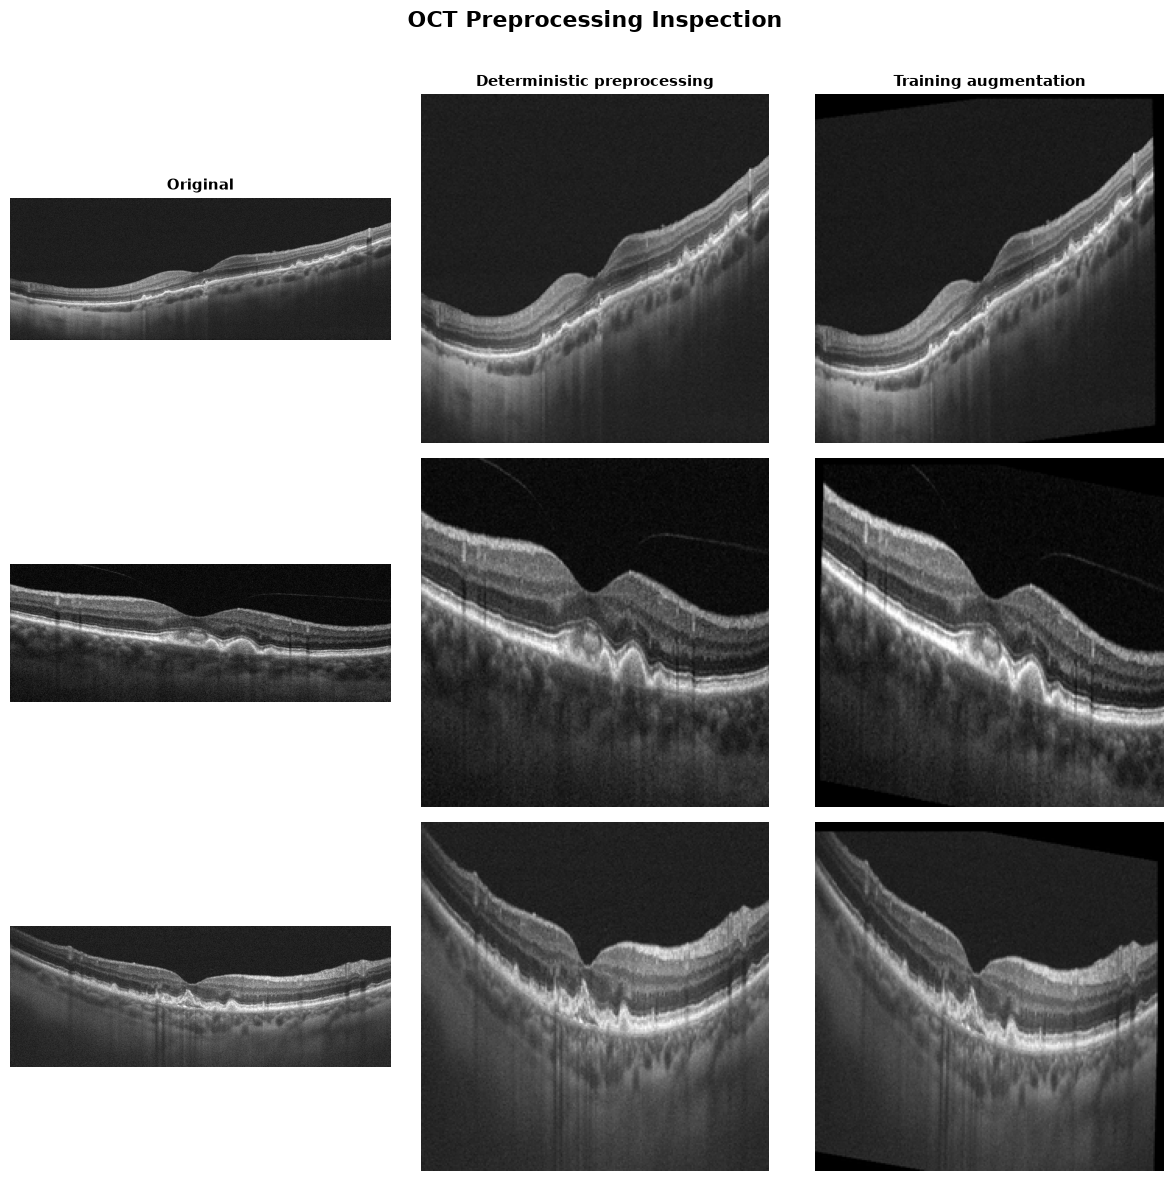

Saved visualization: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\preprocessing_inspection\figures\preprocessing_visual_comparison.png


In [4]:
sample = splits["train"].loc[splits["train"]["disease"] == "AMD"].head(3).copy()
if len(sample) < 3:
    sample = splits["train"].head(3).copy()

visual_rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(sample), 3, figsize=(12, 4 * len(sample)), squeeze=False)
fig.suptitle("OCT Preprocessing Inspection", fontsize=16, fontweight="bold")
column_titles = ["Original", "Deterministic preprocessing", "Training augmentation"]
for column_index, title in enumerate(column_titles):
    axes[0, column_index].set_title(title, fontsize=11, fontweight="bold")
for row_index, (_, record) in enumerate(sample.iterrows()):
    with Image.open(record["image_path_absolute"]) as original:
        original_view = original.convert("L")
    deterministic = validation_preprocess(record["image_path_absolute"])
    augmented = training_preprocess(record["image_path_absolute"], visual_rng)
    axes[row_index, 0].imshow(original_view, cmap="gray")
    axes[row_index, 1].imshow(denormalize_image(deterministic))
    axes[row_index, 2].imshow(denormalize_image(augmented))
    for axis in axes[row_index]:
        axis.axis("off")
    axes[row_index, 0].set_ylabel(str(record["file_name"]), fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.97])
visualization_path = FIGURE_ROOT / "preprocessing_visual_comparison.png"
fig.savefig(visualization_path, bbox_inches="tight")
plt.show()
print(f"Saved visualization: {visualization_path}")

## 6. Validate every split without writing processed images

Each row is passed through its split-specific pipeline in memory. The audit checks tensor shape, finite normalized values, and exceptions that could indicate an unreadable or corrupted input.

In [5]:
validation_rng = np.random.default_rng(42)
validation_rows = []
for split_name, frame in splits.items():
    for _, record in frame.iterrows():
        image_path = record["image_path_absolute"]
        try:
            if split_name == "train":
                array = training_preprocess(image_path, validation_rng)
            else:
                array = preprocessors[split_name](image_path)
            valid = validate_preprocessed_array(array, IMAGE_SIZE)
            validation_rows.append({
                "split": split_name,
                "file_name": record["file_name"],
                "shape": str(tuple(array.shape)),
                "finite": bool(np.isfinite(array).all()),
                "valid": valid,
                "min_value": float(array.min()),
                "max_value": float(array.max()),
                "error": "",
            })
        except Exception as error:
            validation_rows.append({
                "split": split_name,
                "file_name": record["file_name"],
                "shape": "",
                "finite": False,
                "valid": False,
                "min_value": np.nan,
                "max_value": np.nan,
                "error": f"{type(error).__name__}: {error}",
            })

preprocessing_validation = pd.DataFrame(validation_rows)
preprocessing_validation.to_csv(OUTPUT_ROOT / "preprocessing_validation.csv", index=False)

print("Preprocessing validation summary:")
display(preprocessing_validation.groupby("split").agg(
    rows=("file_name", "size"),
    valid_arrays=("valid", "sum"),
    finite_arrays=("finite", "sum"),
).reindex(["train", "validation", "test"]))

error_count = int(preprocessing_validation["error"].fillna("").astype(str).str.strip().ne("").sum())
print(f"Actual preprocessing errors: {error_count}")
if error_count:
    raise AssertionError("At least one image raised an exception during preprocessing.")
if not preprocessing_validation["valid"].all():
    raise AssertionError("At least one image did not produce a valid model-ready array.")
print("All split images produced valid finite arrays with shape (3, 224, 224).")

Preprocessing validation summary:


,rows,valid_arrays,finite_arrays
split,,,
train,1428,1428,1428
validation,327,327,327
test,307,307,307


Actual preprocessing errors: 0
All split images produced valid finite arrays with shape (3, 224, 224).


## 7. Preprocessing summary

This summary records the preprocessing contract for the first baseline model.

In [6]:
summary = pd.DataFrame([
    {
        "input_image_format": "OCT image read by Pillow; source converted to grayscale",
        "output_image_size": "224 x 224 pixels",
        "number_of_channels": 3,
        "normalization_method": "ImageNet mean [0.485, 0.456, 0.406] and std [0.229, 0.224, 0.225] after scaling to [0, 1]",
        "training_augmentations": "rotation +/-5 degrees; brightness/contrast +/-10%; translation up to 3%; no flips/crops/warps",
        "validation_test_method": "grayscale to RGB; resize with LANCZOS; ImageNet normalization; no augmentation",
        "output_array_format": "float32 CHW tensor with shape (3, 224, 224)",
    }
])
summary.to_csv(OUTPUT_ROOT / "preprocessing_summary.csv", index=False)
display(summary.T.rename(columns={0: "baseline_contract"}))
print(f"Saved summary: {OUTPUT_ROOT / 'preprocessing_summary.csv'}")

,baseline_contract
input_image_format,OCT image read by Pillow; source converted to ...
output_image_size,224 x 224 pixels
number_of_channels,3
normalization_method,"ImageNet mean [0.485, 0.456, 0.406] and std [0..."
training_augmentations,rotation +/-5 degrees; brightness/contrast +/-...
validation_test_method,grayscale to RGB; resize with LANCZOS; ImageNe...
output_array_format,"float32 CHW tensor with shape (3, 224, 224)"


Saved summary: C:\Users\vibhu\OneDrive\图片\文档\AMD-Digital-Twin\data\processed\preprocessing_inspection\preprocessing_summary.csv
